# $\textbf{Graduate Trainee Data Science}$
### $\textit{Hamilton M Mataga}$
### matagah3@gmail.com 
### 0776186316

## $\textit{\textbf{EDA \& Business Intelligence}}$

### Import Libraries

In [945]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

### Import Dataset


In [946]:
original_companyx_cdr = pd.read_excel('companyx_cdr.xlsx')
companyx_df= original_companyx_cdr.copy()
companyx_df.head()


,from,to,datetime_stamp,call_duration,status,source_department,destination_department,call_type,rate_per_min,cost
0,412,450,2026-04-15 16:02:19,858,pickedup,Finance,Transport,Internal,0.5,7.15
1,401,339,2026-04-11 14:20:53,1288,pickedup,Marketing,Marketing,Internal,0.5,10.73
2,476,335,2026-03-07 06:25:23,46,pickedup,Marketing,Manufacturing,Internal,0.5,0.38
3,455,437,2026-03-25 04:33:04,0,notpickedup,IT,Finance,Internal,0.5,0.00
4,400,316,2026-07-16 00:39:48,0,notpickedup,Marketing,Manufacturing,Internal,0.5,0.00


In [947]:
# Checking Data Type And Missing Values
companyx_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   from                    1000 non-null   int64         
 1   to                      1000 non-null   int64         
 2   datetime_stamp          1000 non-null   datetime64[ns]
 3   call_duration           1000 non-null   int64         
 4   status                  1000 non-null   object        
 5   source_department       1000 non-null   object        
 6   destination_department  1000 non-null   object        
 7   call_type               1000 non-null   object        
 8   rate_per_min            1000 non-null   float64       
 9   cost                    1000 non-null   float64       
dtypes: datetime64[ns](1), float64(2), int64(3), object(4)
memory usage: 78.2+ KB


In [948]:
# Quick Statistical Summary
companyx_df.describe()

,from,to,call_duration,rate_per_min,cost
count,1000.00000,1000.000000,1000.000000,1000.0,1000.00000
mean,392.13900,392.696000,639.718000,0.5,5.33084
std,55.75669,55.540042,617.847062,0.0,5.14871
min,302.00000,302.000000,0.000000,0.5,0.00000
25%,344.00000,347.000000,0.000000,0.5,0.00000
50%,389.00000,390.000000,512.000000,0.5,4.27000
75%,437.00000,437.000000,1217.500000,0.5,10.14500
max,500.00000,500.000000,1800.000000,0.5,15.00000


In [949]:
companyx_df.isnull().sum()  

from                      0
to                        0
datetime_stamp            0
call_duration             0
status                    0
source_department         0
destination_department    0
call_type                 0
rate_per_min              0
cost                      0
dtype: int64

### Checking for Duplicates

In [950]:
companyx_df.duplicated().sum()

0

### Quick Statistical Insights

In [951]:
numerical_data = companyx_df.select_dtypes(include = 'number')
categorical_data = companyx_df.select_dtypes(include = 'object')

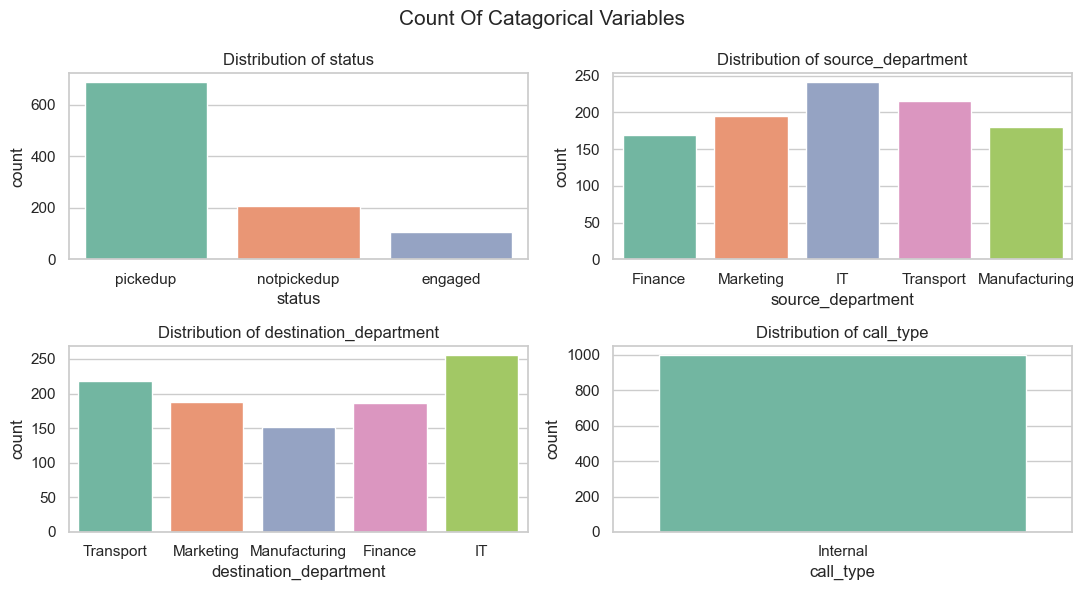

In [952]:
plt.figure(figsize = (11 , 6))
for i, col in enumerate(categorical_data  , 1):
    plt.subplot(2,2,i)
    sns.countplot(data = categorical_data ,  x =col , palette = 'Set2')
    plt.title(f'Distribution of {col}')
    plt.suptitle('Count Of Catagorical Variables' , fontsize = 15)
    plt.tight_layout()
    

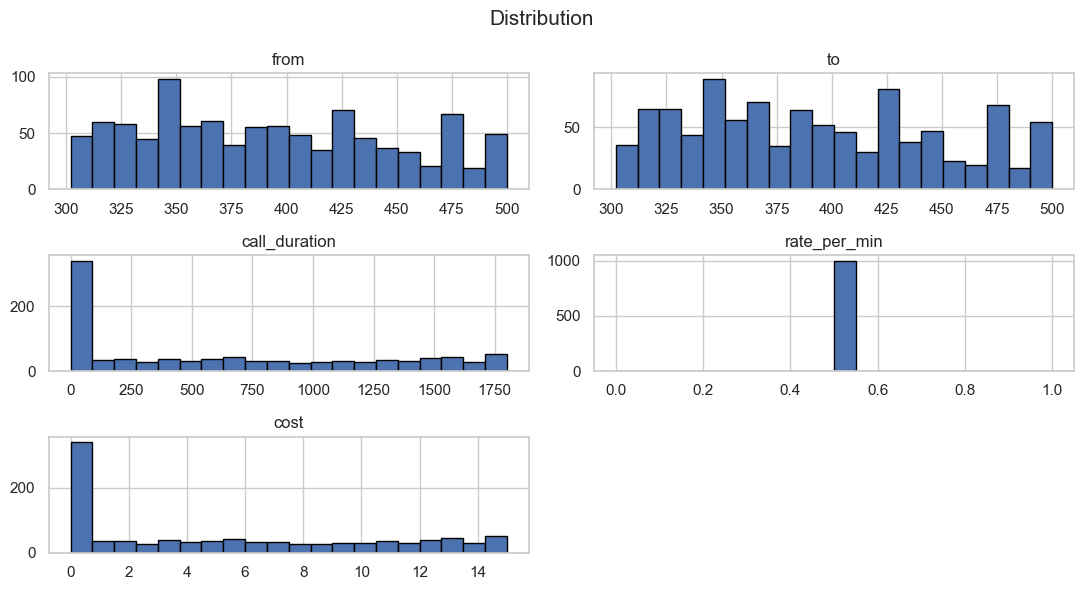

In [953]:
numerical_data.hist(bins = 20 , edgecolor = 'black', figsize = (11,6))
plt.suptitle('Distribution' , fontsize =15)
plt.tight_layout()

### $\textbf{Question 1}$
- $\textbf{ Which deartment makes the most calls, and which receives the most calls ?}$

In [954]:
companyx_df['source_department'].value_counts().sort_values(ascending = False).reset_index()

,index,source_department
0,IT,241
1,Transport,215
2,Marketing,195
3,Manufacturing,180
4,Finance,169


- The department that makes the most calls is IT department with a total number of 241 calls

In [955]:
companyx_df['destination_department'].value_counts().sort_values(ascending = False).reset_index()

,index,destination_department
0,IT,256
1,Transport,218
2,Marketing,188
3,Finance,186
4,Manufacturing,152


- The department that receives the most calls is IT department with total number of 256 calls

### $\textbf{Question 2}$

- $\textbf{What is the overall pickup rate ?}$
- To calculate the overall picked up rate , calculate the total picked up calls by filtering only the picked up calls and then divide by the total call from the whole dataset

In [956]:
# Filtering only by pickedup calls
pickedup_df = companyx_df[companyx_df['status'] == 'pickedup']

# Total Calls
total_calls = companyx_df['status'].count()
total_calls

# Total pickedup Calls
total_pickedup_calls =pickedup_df['status'].count()
total_pickedup_calls

# Overall Pickedup Rate

overall_pickup_rate = (total_pickedup_calls / total_calls)*100

print(f'{overall_pickup_rate}%')


68.8%


- The overall pickedup rate is 0.69

### $\textbf{Question 3}$
- $\textbf{Which department is the most expensive to run in terms of communication costs ?}$
- Group by the departments and the cost 

In [957]:
companyx_df.groupby('source_department')['cost'].sum().sort_values(ascending = False)

source_department
IT               1268.65
Marketing        1117.40
Manufacturing     992.08
Transport         979.88
Finance           972.83
Name: cost, dtype: float64

- IT department is the most expensive to run with a total cost of 1268.65

## $\textbf{Visualisation}$

- Expanding my datetime Column

In [958]:
companyx_df = companyx_df.sort_values(by='datetime_stamp' , ascending = True)

In [959]:
companyx_df['Month_name'] = companyx_df['datetime_stamp'].dt.strftime('%B')
companyx_df['Month_num'] = companyx_df['datetime_stamp'].dt.month
companyx_df['Hour'] = companyx_df['datetime_stamp'].dt.hour
companyx_df['Day']  = companyx_df['datetime_stamp'].dt.day_name()

In [960]:
companyx_df['Day_num']  = companyx_df['datetime_stamp'].dt.strftime('%d')

In [961]:
# Creating a copy dataset with indexed date
companyx_df.head()
company_data = companyx_df.copy()
company_data.set_index(company_data['datetime_stamp'] , inplace = True)

In [962]:
company_data.head()

,from,to,datetime_stamp,call_duration,status,source_department,destination_department,call_type,rate_per_min,cost,Month_name,Month_num,Hour,Day,Day_num
datetime_stamp,,,,,,,,,,,,,,,
2026-01-01 09:43:20,394,444,2026-01-01 09:43:20,0,engaged,Manufacturing,IT,Internal,0.5,0.00,January,1,9,Thursday,01
2026-01-01 10:30:08,356,379,2026-01-01 10:30:08,0,notpickedup,IT,Marketing,Internal,0.5,0.00,January,1,10,Thursday,01
2026-01-01 11:42:05,469,384,2026-01-01 11:42:05,388,pickedup,Manufacturing,IT,Internal,0.5,3.23,January,1,11,Thursday,01
2026-01-01 18:08:11,391,495,2026-01-01 18:08:11,396,pickedup,Finance,Marketing,Internal,0.5,3.30,January,1,18,Thursday,01
2026-01-01 20:25:26,350,328,2026-01-01 20:25:26,629,pickedup,Transport,Transport,Internal,0.5,5.24,January,1,20,Thursday,01


### $ \textbf{Calls Per Hour}$
- Using the indexed datetime to group by hours of the day and the count of calls

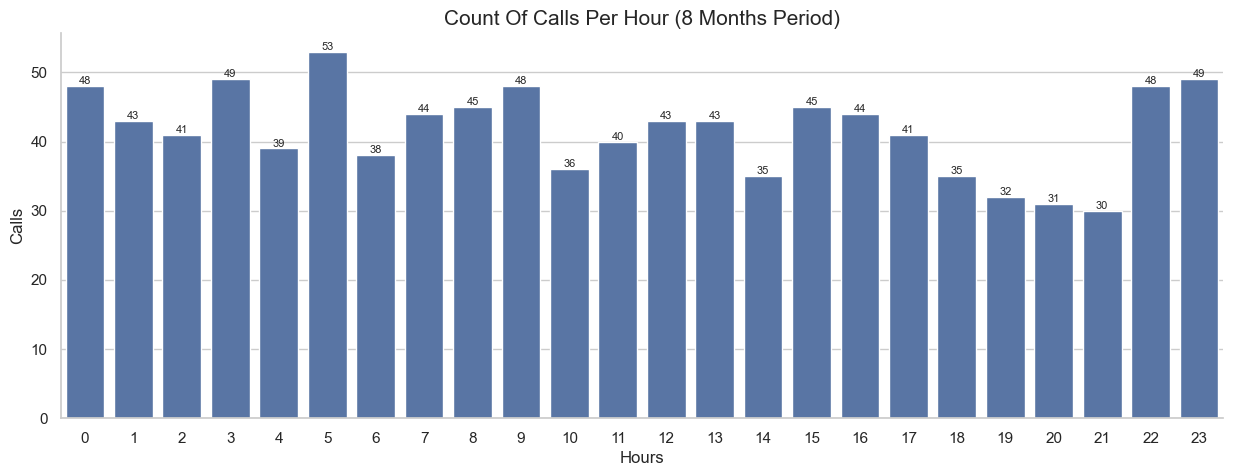

In [963]:
hourly_calls = company_data.groupby(company_data.index.hour).size().reset_index(name = 'Count')
sns.set_theme(style="whitegrid", palette="deep")
fig, ax = plt.subplots(figsize=(15, 5))
sns.barplot(data  =hourly_calls , x = 'datetime_stamp' , y = 'Count' , ax = ax  , color = '#4C72B0'  )
ax.bar_label(ax.containers[0], fontsize=8)
plt.title('Count Of Calls Per Hour (8 Months Period)' , fontsize = 15)
sns.despine()
plt.ylabel('Calls')
plt.xlabel('Hours')
#plt.xlim(0,24)
plt.show()

### $\textbf{Calls Per Day}$
- Using a combined plot to show the volumes of calls per day and their relative distribution throughout the 8 months period.

In [964]:
companyx_df.head()
company_data = companyx_df.copy()
company_data.set_index(company_data['datetime_stamp'] , inplace = True)

In [965]:
company_data['Date_time'] = company_data['datetime_stamp'].dt.strftime('%Y-%m-%d')

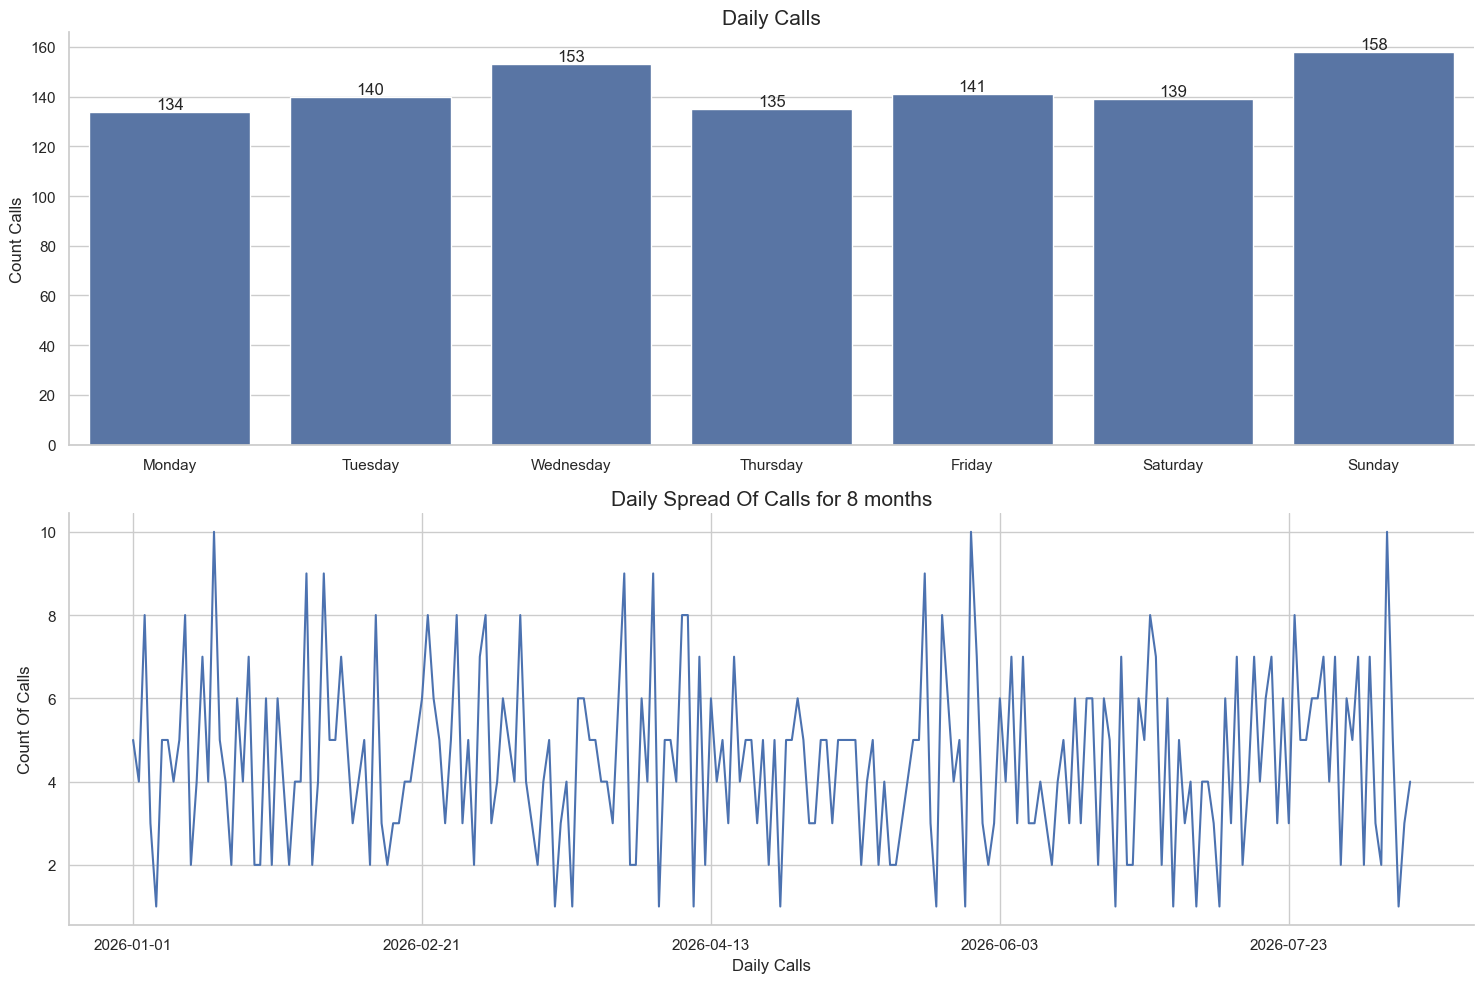

In [966]:
# Extracting Day Name from indexed datetime and Maintaining the actual order
chrono_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
grp_dates = company_data.groupby(company_data.index.day_name()).size().reindex(chrono_order)

# Putting the plot that shows Daily Calls in Days of the Week and Plot the daily spread of calls for the 8 Months period
fig, (ax1 , ax2) = plt.subplots( 2,1,figsize=(15, 10))
sns.despine()
sns.barplot( x = grp_dates.index , y = grp_dates.values , ax = ax1 , color = '#4C72B0' )
ax1.bar_label(ax1.containers[0], fontsize=12)
ax1.set_title('Daily Calls' , fontsize = 15)
ax1.set_ylabel('Count Calls')
ax1.set_xlabel('')
company_data.groupby('Date_time').size().plot(kind = 'line'  ,ax = ax2  )
ax2.set_title('Daily Spread Of Calls for 8 months' , fontsize = 15)
ax2.set_ylabel('Count Of Calls')
ax2.set_xlabel('Daily Calls')
plt.tight_layout()
plt.show()

- Sunday is show a large amount of calls and the overall spread of calls per Day varies between 0 and 10 calls for the 8 months period

### $\textbf{Monthly Calls Per Department}$
- Pivoting the data using month as index , department as columns and values is the count of calls

In [967]:
company_data['Month_name'].unique().tolist()

['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August']

Text(0.5, 0, '')

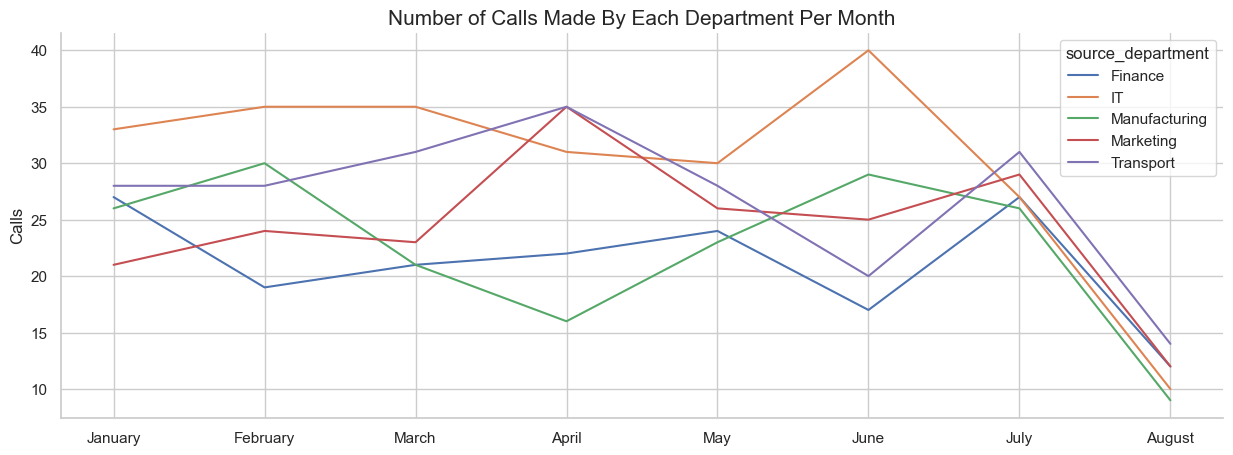

In [968]:
order1 = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August']
company_data.pivot_table(index = 'Month_name' , columns = 'source_department',
                         values = 'status' , aggfunc = 'count').reindex(order1).plot(kind = 'line', figsize=(15, 5))
sns.set_theme(style="ticks", palette="deep")
sns.despine()
plt.title('Number of Calls Made By Each Department Per Month' , fontsize = 15)
plt.ylabel('Calls')
plt.xlabel('')

- IT Department has a considerable high amounts of calls for the entire 8 months period.

# $\textbf{Predictive Modeling}$

### Testing Various Models To Determine the Best Model To Use

In [969]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix,
                              classification_report, RocCurveDisplay)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

### Feature Engineering

- Removing the engaged option and converting it to notpicked up

In [970]:
companyx_df['status'] = companyx_df['status'].str.replace('engaged','notpickedup')
companyx_df['status'].unique()

array(['notpickedup', 'pickedup'], dtype=object)

- Creating hours , day of the week and month column

In [971]:
companyx_df["hour"] = companyx_df["datetime_stamp"].dt.hour
companyx_df["dayofweek"] = companyx_df["datetime_stamp"].dt.dayofweek
companyx_df["month"] = companyx_df["datetime_stamp"].dt.month

- Converting $\textit{dependent}$ variable(Y) to numeric 

In [972]:
y = companyx_df["status"].map({"pickedup": 1, "notpickedup": 0})

- Selecting $\textit{independing}$ Variables

In [973]:

feature_cols = ["from", "to",'call_duration', "source_department", "destination_department",
                 "rate_per_min",'cost', "hour", "dayofweek", "month"]
X = companyx_df[feature_cols]
X.head()

,from,to,call_duration,source_department,destination_department,rate_per_min,cost,hour,dayofweek,month
504,394,444,0,Manufacturing,IT,0.5,0.00,9,3,1
617,356,379,0,IT,Marketing,0.5,0.00,10,3,1
241,469,384,388,Manufacturing,IT,0.5,3.23,11,3,1
219,391,495,396,Finance,Marketing,0.5,3.30,18,3,1
97,350,328,629,Transport,Transport,0.5,5.24,20,3,1


In [974]:

X.columns

Index(['from', 'to', 'call_duration', 'source_department',
       'destination_department', 'rate_per_min', 'cost', 'hour', 'dayofweek',
       'month'],
      dtype='object')

## Scaling and Encoding

- Standard Scaler is for scaling numbers so that that there is no big number differencies .
- Encoding is for converting categorical variables into dummy quatifiable variable.

In [975]:
num_col = ['from', 'to', 'rate_per_min', 'hour', 'dayofweek', 'month']
cat_col = ['source_department', 'destination_department']



preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_col),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_col)
])

- Train Test Split

In [976]:
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42, stratify=y)

print("Train size:", X_train.shape, " Test size:", X_test.shape)


Train size: (800, 10)  Test size: (200, 10)


### Comparing Many Models to Choose the Suitable

In [977]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(probability=True, random_state=42),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Naive Bayes": GaussianNB()
}

### Training The Models

In [978]:
results = []
fitted_pipelines = {}

for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    fitted_pipelines[name] = pipe

    preds = pipe.predict(X_test)
    proba = (pipe.predict_proba(X_test)[:, 1]
             if hasattr(pipe.named_steps["model"], "predict_proba") else None)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds, zero_division=0),
        "Recall": recall_score(y_test, preds, zero_division=0),
        "F1": f1_score(y_test, preds, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, proba) if proba is not None else np.nan
    })

results_df = pd.DataFrame(results).sort_values("F1", ascending=False).reset_index(drop=True)
results_df

c:\Users\user\anaconda3\lib\site-packages\sklearn\neighbors\_classification.py:228: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  mode, _ = stats.mode(_y[neigh_ind, k], axis=1)


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Naive Bayes,0.700,0.701031,0.985507,0.819277,0.513324
1,SVM,0.695,0.693467,1.000000,0.818991,0.478144
2,Logistic Regression,0.690,0.690000,1.000000,0.816568,0.529336
3,Random Forest,0.675,0.697297,0.934783,0.798762,0.509000
4,KNN,0.610,0.682927,0.811594,0.741722,0.508123
5,Decision Tree,0.560,0.701613,0.630435,0.664122,0.516830


In [979]:
best_model_name = results_df.iloc[0]["Model"]
best_pipeline = fitted_pipelines[best_model_name]

print(f"Best model: {best_model_name}")
results_df

Best model: Naive Bayes


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Naive Bayes,0.700,0.701031,0.985507,0.819277,0.513324
1,SVM,0.695,0.693467,1.000000,0.818991,0.478144
2,Logistic Regression,0.690,0.690000,1.000000,0.816568,0.529336
3,Random Forest,0.675,0.697297,0.934783,0.798762,0.509000
4,KNN,0.610,0.682927,0.811594,0.741722,0.508123
5,Decision Tree,0.560,0.701613,0.630435,0.664122,0.516830


- After comparing the models it is clear that the Naive Bayes Classification is the best at classifying this data

### NAIVE BAYES CLASSIFICATION

-Importing Libraries

In [980]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,f1_score, roc_auc_score, confusion_matrix,
                              classification_report)

In [981]:
companyx_df.head()


,from,to,datetime_stamp,call_duration,status,source_department,destination_department,call_type,rate_per_min,cost,Month_name,Month_num,Hour,Day,Day_num,hour,dayofweek,month
504,394,444,2026-01-01 09:43:20,0,notpickedup,Manufacturing,IT,Internal,0.5,0.00,January,1,9,Thursday,01,9,3,1
617,356,379,2026-01-01 10:30:08,0,notpickedup,IT,Marketing,Internal,0.5,0.00,January,1,10,Thursday,01,10,3,1
241,469,384,2026-01-01 11:42:05,388,pickedup,Manufacturing,IT,Internal,0.5,3.23,January,1,11,Thursday,01,11,3,1
219,391,495,2026-01-01 18:08:11,396,pickedup,Finance,Marketing,Internal,0.5,3.30,January,1,18,Thursday,01,18,3,1
97,350,328,2026-01-01 20:25:26,629,pickedup,Transport,Transport,Internal,0.5,5.24,January,1,20,Thursday,01,20,3,1


In [982]:
# Date Time
companyx_df["hour"] = companyx_df["datetime_stamp"].dt.hour
companyx_df["dayofweek"] = companyx_df["datetime_stamp"].dt.dayofweek
companyx_df["month"] = companyx_df["datetime_stamp"].dt.month

#Changing status to pickedup and notpickedup and transform to 0 and 1
companyx_df['status'] = companyx_df['status'].str.replace('engaged','notpickedup')
companyx_df["status"] =companyx_df["status"].map({"pickedup": 1, "notpickedup": 0})

# Picking X and y
X = companyx_df[["from", "to",'call_duration', "source_department", "destination_department",
                 'cost', "hour", "dayofweek", "month"]]

y = companyx_df['status']

In [983]:
categorical = ["source_department", "destination_department"]
numeric = ["from", "to", "hour", "dayofweek", "month"]

## Feature Engineering

In [984]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical)
])

## Train Test Split

In [985]:
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (800, 9)  Test: (200, 9)


In [986]:
X_train.head()

,from,to,call_duration,source_department,destination_department,cost,hour,dayofweek,month
343,459,379,0,Marketing,Marketing,0.00,9,0,1
611,466,489,0,Transport,Finance,0.00,5,5,3
162,392,459,1731,Transport,Marketing,14.43,9,0,4
964,303,342,955,Marketing,Finance,7.96,15,5,5
414,473,342,1715,Marketing,Finance,14.29,18,6,8


## Model Training

In [987]:
pipe = Pipeline([("prep", preprocessor), ("model", GaussianNB())])
pipe.fit(X_train, y_train)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['from', 'to', 'hour',
                                                   'dayofweek', 'month']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['source_department',
                                                   'destination_department'])])),
                ('model', GaussianNB())])

In [988]:
y_test.head()

565    0
984    1
254    1
488    1
499    1
Name: status, dtype: int64

In [989]:
y_pred = pipe.predict(X_test)
y_proba = pipe.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_proba))
print(classification_report(y_test, y_pred, target_names=["notpickedup", "pickedup"]))

Accuracy: 0.7
Precision: 0.7010309278350515
Recall: 0.9855072463768116
F1: 0.8192771084337348
ROC-AUC: 0.5133239831697054
              precision    recall  f1-score   support

 notpickedup       0.67      0.06      0.12        62
    pickedup       0.70      0.99      0.82       138

    accuracy                           0.70       200
   macro avg       0.68      0.53      0.47       200
weighted avg       0.69      0.70      0.60       200



In [990]:
confusion_matrix(y_test, y_pred)

array([[  4,  58],
       [  2, 136]], dtype=int64)

- The result show that most of the time the call will be picked up 69% of calls are picked up and the rest falls to not picked up calls this is consistant with the data since a large portion of the data is of picked up calls

In [991]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

perm_result = permutation_importance(pipe, X_test, y_test,n_repeats=20, random_state=42, scoring="roc_auc")

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std
}).sort_values("importance_mean", ascending=False)


importance_df

,feature,importance_mean,importance_std
7,dayofweek,0.003471,0.002830
6,hour,0.003319,0.004035
8,month,0.001788,0.005077
2,call_duration,0.000000,0.000000
5,cost,0.000000,0.000000
0,from,-0.001169,0.001266
1,to,-0.002080,0.004835
3,source_department,-0.008211,0.025947
4,destination_department,-0.012161,0.031765


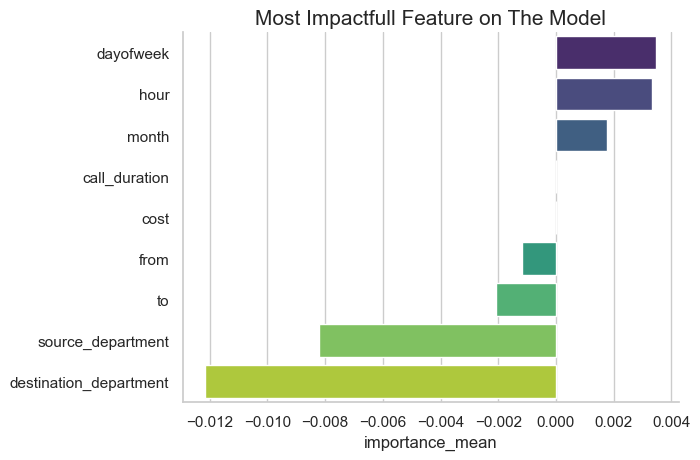

In [992]:
sns.barplot(data = importance_df , x = 'importance_mean' , y = 'feature' , palette = 'viridis')
plt.title('Most Impactfull Feature on The Model' , fontsize = 15)
plt.ylabel('')
sns.despine()

- The variable showing a negative mean can easily be removed and train the model again since they dont have any effect

# Part 3
## Time Series Forecasting Using ARIMA

In [993]:
companyx_df.head()
company_data = companyx_df.copy()

In [994]:
#company_data.set_index(company_data['datetime_stamp'] , inplace = True)
company_data['Date_time'] = company_data['datetime_stamp'].dt.strftime('%Y-%m-%d')


In [995]:
company_data.head()

,from,to,datetime_stamp,call_duration,status,source_department,destination_department,call_type,rate_per_min,cost,Month_name,Month_num,Hour,Day,Day_num,hour,dayofweek,month,Date_time
504,394,444,2026-01-01 09:43:20,0,0,Manufacturing,IT,Internal,0.5,0.00,January,1,9,Thursday,01,9,3,1,2026-01-01
617,356,379,2026-01-01 10:30:08,0,0,IT,Marketing,Internal,0.5,0.00,January,1,10,Thursday,01,10,3,1,2026-01-01
241,469,384,2026-01-01 11:42:05,388,1,Manufacturing,IT,Internal,0.5,3.23,January,1,11,Thursday,01,11,3,1,2026-01-01
219,391,495,2026-01-01 18:08:11,396,1,Finance,Marketing,Internal,0.5,3.30,January,1,18,Thursday,01,18,3,1,2026-01-01
97,350,328,2026-01-01 20:25:26,629,1,Transport,Transport,Internal,0.5,5.24,January,1,20,Thursday,01,20,3,1,2026-01-01


In [996]:
daily = company_data.set_index('datetime_stamp').resample('D').agg( from1 = ('from' , 'count'),
                                cost = ('cost','sum') )

In [997]:
daily.rename(columns = {'from1':'from'} , inplace = True)

In [998]:
daily_totals = daily.copy()

### $\textbf{Moving Averages and Exponentials}$

In [999]:
daily_totals['from_moving_avg'] = daily_totals['from'].rolling(window=4 ).mean() # Change data when using different data

In [1000]:
daily_totals['exp_moving_avg'] = daily_totals['from'].ewm(alpha=0.2).mean() 


In [1001]:
daily_totals['cost_moving_avg'] = daily_totals['cost'].rolling(window=4 ).mean() 
daily_totals['exp_cost'] = daily_totals['cost'].ewm(alpha=0.2).mean() 

In [1002]:
daily_totals.dropna(inplace = True)

In [1003]:
daily_totals

,from,cost,from_moving_avg,exp_moving_avg,cost_moving_avg,exp_cost
datetime_stamp,,,,,,
2026-01-04,3,40.56,5.00,4.918699,31.8900,34.377995
2026-01-05,1,12.23,4.00,3.752975,32.0050,27.789467
2026-01-06,5,10.93,4.25,4.090988,26.4775,23.219614
2026-01-07,5,33.49,3.50,4.321035,24.3025,25.818775
2026-01-08,4,20.68,3.75,4.243884,19.3325,24.583831
...,...,...,...,...,...,...
2026-08-09,10,48.43,5.50,5.394110,24.2300,23.312137
2026-08-10,5,25.20,5.00,5.315288,23.1350,23.689709
2026-08-11,1,0.00,4.50,4.452230,21.8350,18.951767


In [1004]:
daily_totals.columns

Index(['from', 'cost', 'from_moving_avg', 'exp_moving_avg', 'cost_moving_avg',
       'exp_cost'],
      dtype='object')

<AxesSubplot:xlabel='datetime_stamp'>

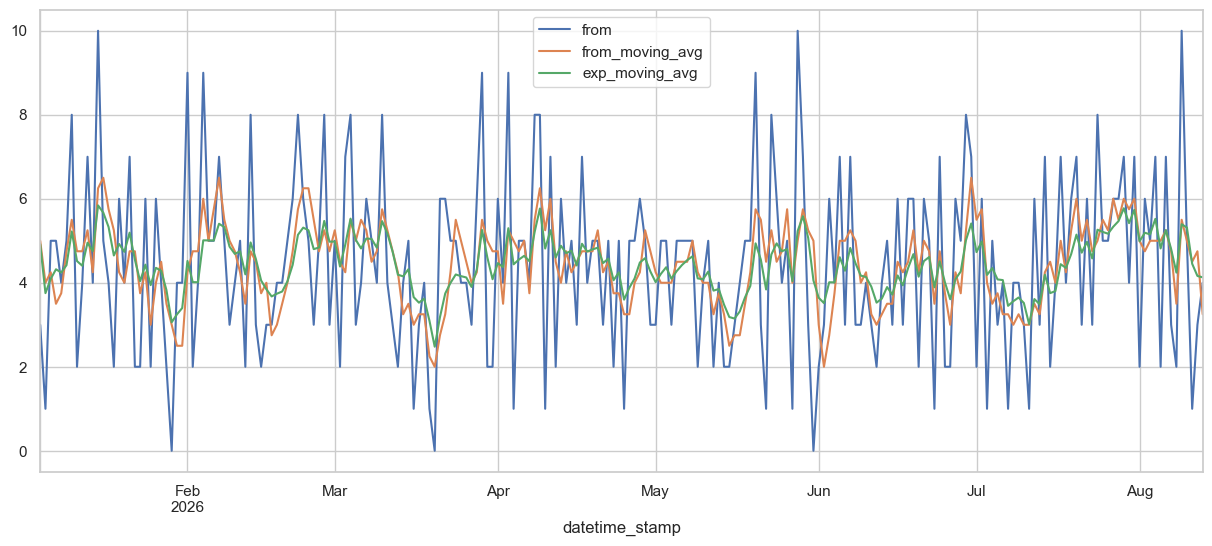

In [1005]:

daily_totals.loc[:, ['from','from_moving_avg', 'exp_moving_avg']].plot(kind = 'line' , figsize = (15 ,6))

<AxesSubplot:xlabel='datetime_stamp'>

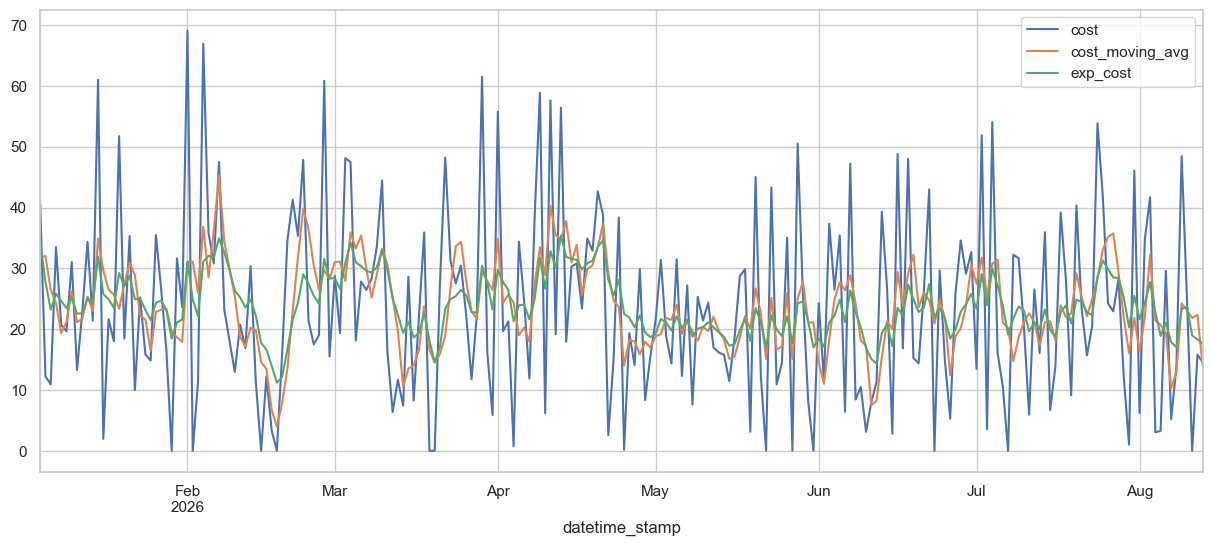

In [1006]:
daily_totals.loc[:, ['cost','cost_moving_avg', 'exp_cost']].plot(kind = 'line' , figsize = (15 ,6))

## $\textbf{ARIMA}$

In [1007]:
data_arima = daily.copy()
data_arima

,from,cost
datetime_stamp,,
2026-01-01,5,11.77
2026-01-02,4,33.04
2026-01-03,8,42.19
2026-01-04,3,40.56
2026-01-05,1,12.23
...,...,...
2026-08-09,10,48.43
2026-08-10,5,25.20
2026-08-11,1,0.00


In [1008]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima_model import ARIMA
from statsmodels.tsa.arima.model import ARIMA

- $\textbf{Testing Stationarity}$
- Using Dicky Fuller Test

Null Hypothesis  = 1(the time series is non stationary)\
Alternative Hypothesis < 1(the time series is stationary)


In [1009]:
from statsmodels.tsa.stattools import adfuller

In [1010]:
dftest = adfuller(data_arima['from'] , autolag = 'AIC' )

dfoutput = pd.Series(dftest[0:4],
                             index = ['Test Statistic',
                                      'p-value',
                                      'Lags Used',
                                      'Number of Observation'])
print(dfoutput)

Test Statistic          -1.692168e+01
p-value                  9.929188e-30
Lags Used                0.000000e+00
Number of Observation    2.240000e+02
dtype: float64


- p value is less than 0.05 we reject Null Hypothesis and conclude that the series is stationary this implies that there is no need to difference our data so our order becomes (p ,0, q).

In [1011]:
dftest = adfuller(data_arima['cost'] , autolag = 'AIC' )

dfoutput = pd.Series(dftest[0:4],
                             index = ['Test Statistic',
                                      'p-value',
                                      'Lags Used',
                                      'Number of Observation'])
print(dfoutput)

Test Statistic          -1.704955e+01
p-value                  8.088362e-30
Lags Used                0.000000e+00
Number of Observation    2.240000e+02
dtype: float64


-p value is less than 0.05 we reject Null Hypothesis and conclude that the series is stationary

In [1012]:
data_arima

,from,cost
datetime_stamp,,
2026-01-01,5,11.77
2026-01-02,4,33.04
2026-01-03,8,42.19
2026-01-04,3,40.56
2026-01-05,1,12.23
...,...,...
2026-08-09,10,48.43
2026-08-10,5,25.20
2026-08-11,1,0.00


In [1013]:
data_arima_train = data_arima[:120]
data_arima_test = data_arima[120:]

### PACF AND ACF PLOTS

- Autocorrelation check for the number of calls and AR(p) and MA(q) determining

c:\Users\user\anaconda3\lib\site-packages\statsmodels\graphics\tsaplots.py:348: FutureWarning: The default method 'yw' can produce PACF values outside of the [-1,1] interval. After 0.13, the default will change tounadjusted Yule-Walker ('ywm'). You can use this method now by setting method='ywm'.
  warnings.warn(


Figure(640x480)
Figure(640x480)


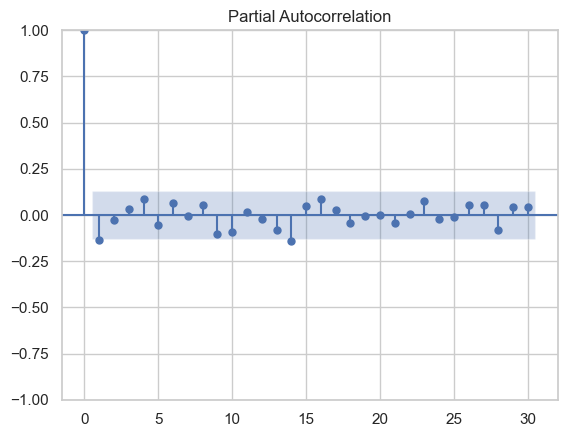

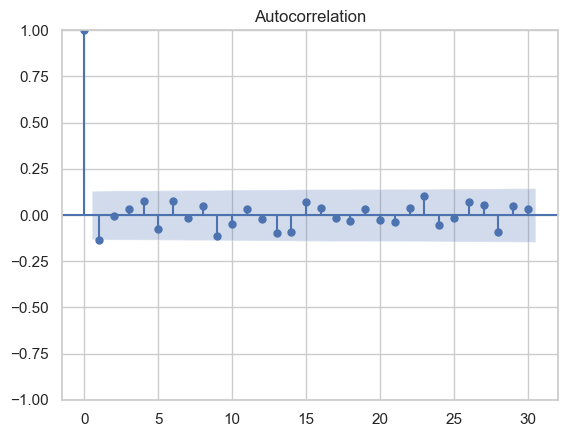

In [1014]:
pacf_plot = plot_pacf(data_arima['cost'] , lags=30)
acf_plot =plot_acf(data_arima['cost'] , lags=30)
print(pacf_plot)
print(acf_plot)

- Since there is no autocorrelation and the graphs gradually decreases to zero , it provides us with the values of p and q and according to the graphs we can choose 1 for p and q.

### Arima Model Deploying

- The acf plot decreases gradually which is a sign of stationarity

In [1015]:
arima = ARIMA(data_arima['from'] , order = (1,0,1))
arima_model = arima.fit()
arima_model.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                   from   No. Observations:                  225
Model:                 ARIMA(1, 0, 1)   Log Likelihood                -485.771
Date:                Mon, 17 Aug 2026   AIC                            979.542
Time:                        14:44:28   BIC                            993.207
Sample:                    01-01-2026   HQIC                           985.057
                         - 08-13-2026                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.4446      0.124     35.897      0.000       4.202       4.687
ar.L1          0.0898      0.543      0.165      0.869      -0.974       1.154
ma.L1         -0.2204      0.537     -0.410      0.682      -1.273       0.832
sigma2         4.3930      0.459      9.575      0.000       3.494       5.292
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):                 3.32
Prob(Q):                              1.00   Prob(JB):                         0.19
Heteroskedasticity (H):               0.97   Skew:                             0.27
Prob(H) (two-sided):                  0.89   Kurtosis:                         2.73
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

- p value less than 0.05 shows the model is significant.

In [1016]:
arima = ARIMA(data_arima['cost'] , order = (1,0,1))
arima_model1 = arima.fit()
arima_model1.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                   cost   No. Observations:                  225
Model:                 ARIMA(1, 0, 1)   Log Likelihood                -932.776
Date:                Mon, 17 Aug 2026   AIC                           1873.552
Time:                        14:44:28   BIC                           1887.217
Sample:                    01-01-2026   HQIC                          1879.067
                         - 08-13-2026                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         23.7030      0.971     24.408      0.000      21.800      25.606
ar.L1         -0.0263      0.494     -0.053      0.958      -0.995       0.943
ma.L1         -0.1095      0.494     -0.222      0.825      -1.077       0.858
sigma2       233.5737     25.134      9.293      0.000     184.311     282.836
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):                10.24
Prob(Q):                              1.00   Prob(JB):                         0.01
Heteroskedasticity (H):               0.89   Skew:                             0.51
Prob(H) (two-sided):                  0.61   Kurtosis:                         2.80
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

- p value less than 0.05 shows the model is significant.

### Checking Autocorrelation From Model Residuals

c:\Users\user\anaconda3\lib\site-packages\statsmodels\graphics\tsaplots.py:348: FutureWarning: The default method 'yw' can produce PACF values outside of the [-1,1] interval. After 0.13, the default will change tounadjusted Yule-Walker ('ywm'). You can use this method now by setting method='ywm'.
  warnings.warn(


Figure(640x480)


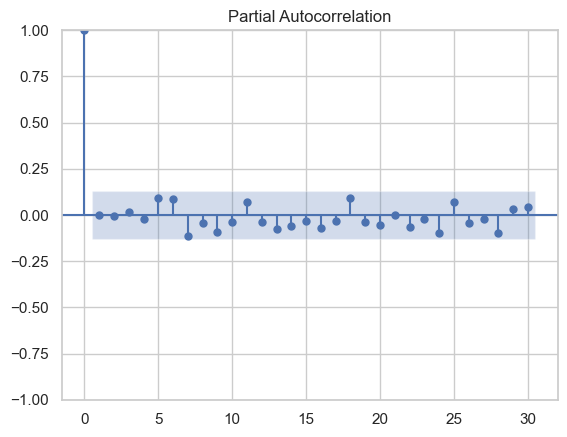

In [1017]:
pacf_plot = plot_pacf(arima_model.resid , lags=30)
#acf_plot =plot_acf(arima_model.resid , lags=30)
print(pacf_plot)


- No autocorrelation the model is valid

Figure(640x480)


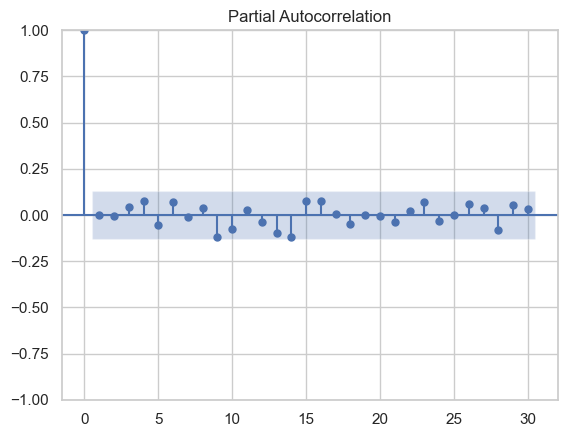

In [1018]:
pacf_plot = plot_pacf(arima_model1.resid , lags=30)
#acf_plot =plot_acf(arima_model1.resid , lags=30)
print(pacf_plot)


- No autocorrelation the model is valid

### Forecast And Measure Accuracy

In [1019]:
data_arima.shape

(225, 2)

Text(0.5, 1.0, 'RSS: 52550.6991')

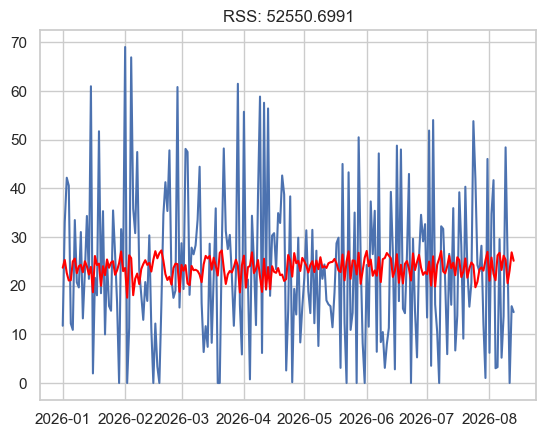

In [1020]:
plt.plot(data_arima['cost'] )
plt.plot(arima_model1.fittedvalues , color = 'red')
plt.title("RSS: %.4f"% sum((arima_model1.fittedvalues-data_arima['cost'])**2))

Text(0.5, 1.0, 'RSS: 988.4268')

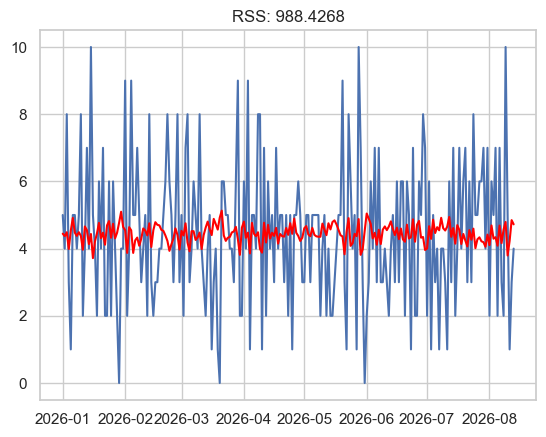

In [1021]:
plt.plot(data_arima['from'] )
plt.plot(arima_model.fittedvalues , color = 'red')
plt.title("RSS: %.4f"% sum((arima_model.fittedvalues-data_arima['from'])**2))

- The actual data in blue is significantly different from the red which is the predicted so the error margin is significantly large.

### $\textbf{Predictions}$

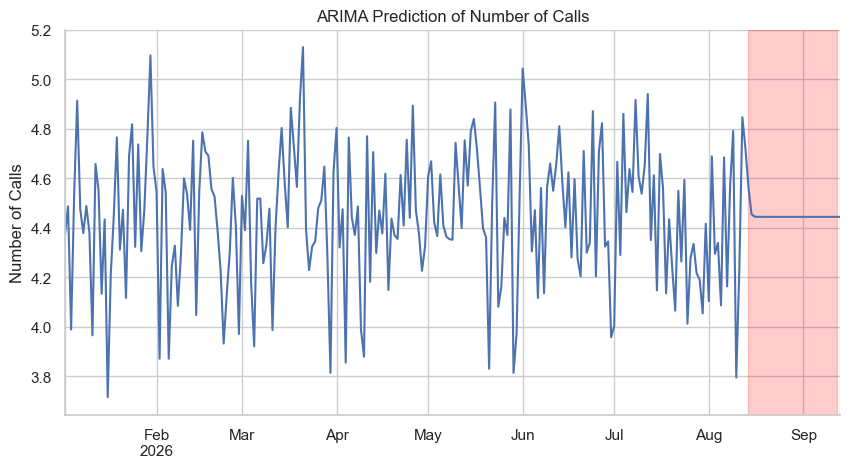

In [1022]:
arima_model.predict(start = 1 , end = 255).plot(figsize = (10 ,5) , title = 'ARIMA Prediction of Number of Calls')
plt.axvspan('2026-08-14' ,'2026-09-12',  color = 'red' , alpha = .2  )

plt.ylabel('Number of Calls')
sns.despine()
plt.show()

In [1023]:
forec_30 = arima_model.forecast(steps = 30)
forec_30.mean()

4.448999738938411

- The forecasted number of calls per day between August and September have a average of 4 calls per day

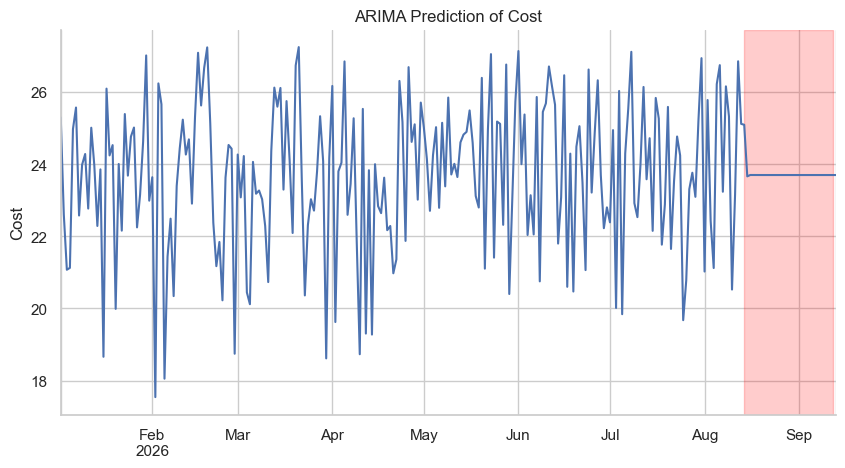

In [1024]:
arima_model1.predict(start = 1 , end = 255).plot(figsize = (10 ,5) , title = 'ARIMA Prediction of Cost')
plt.axvspan('2026-08-14' ,'2026-09-12',  color = 'red' , alpha = .2  )
sns.despine()
plt.ylabel('Cost')
plt.show()

In [1025]:
forecast_30 = arima_model1.forecast(steps =30)
forecast_30.mean()

23.74833665306851

- The predicted cost of calls averaged 24 

### Measure Accuracy

In [1026]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [1027]:
print(mean_absolute_error(data_arima['from'][-30:] ,  forec_30.values  ))
print(np.sqrt(mean_absolute_error(data_arima['from'][-30:] ,  forec_30.values  )))
print(get_mape(data_arima['from'][-30:] ,  forec_30.values  ))

1.8450162906711107
1.3583137673862806
52.33


- The Accuracy test shows that the is a considerable difference between the predicted and the actual values which implies that the model is not performing well.
- The mean absolute percentage error is above 50% which is no a good prediction value.